In [ ]:
 !pip install -q lime scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 11.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms
from lime import lime_image
from skimage.segmentation import mark_boundaries

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
# Pretrained model + ImageNet class names
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights).to(device).eval()
class_names = weights.meta["categories"]

# Same pixels for LIME and the model: resize to 224x224, then normalise
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


Saving a-vibrant-scene-of-colorful-birds-perched-on-a-branch-during-sunset-photo.webp to a-vibrant-scene-of-colorful-birds-perched-on-a-branch-during-sunset-photo.webp


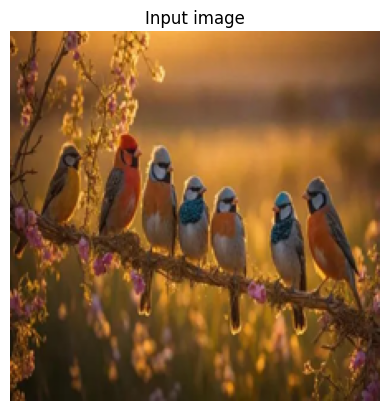

In [ ]:
# Upload ANY image (Colab) -- or set IMG_PATH to a local file when running in Jupyter
try:
    from google.colab import files
    uploaded = files.upload()
    IMG_PATH = list(uploaded.keys())[0]
except ImportError:
    IMG_PATH = "your_image.jpg"      # <- change this

img_pil = Image.open(IMG_PATH).convert("RGB").resize((224, 224))
img_lime = np.array(img_pil).astype(np.float64) / 255.0     # HWC, float in [0,1]

plt.imshow(img_pil); plt.axis("off"); plt.title("Input image"); plt.show()

In [ ]:
# Model's top-5 predictions
with torch.no_grad():
    p = model(preprocess(img_pil).unsqueeze(0).to(device)).softmax(1)[0].cpu()
top_p, top_i = p.topk(5)
for pr, i in zip(top_p, top_i):
    print(f"{class_names[i]:30s} {pr:.3f}")

brambling                      0.221
robin                          0.102
indigo bunting                 0.014
black grouse                   0.007
partridge                      0.007


In [ ]:
def batch_predict(images, bs=32):
    """LIME calls this with perturbed images (HWC, float [0,1]); returns probs [N, 1000]."""
    model.eval()
    out = []
    for i in range(0, len(images), bs):
        chunk = images[i:i + bs]
        batch = torch.stack([preprocess(Image.fromarray((im * 255).astype(np.uint8)))
                             for im in chunk]).to(device)
        with torch.no_grad():
            out.append(model(batch).softmax(dim=1).cpu().numpy())
    return np.concatenate(out)

In [ ]:
explainer = lime_image.LimeImageExplainer(random_state=42)
explanation = explainer.explain_instance(
    img_lime, batch_predict,
    top_labels=5, hide_color=0,
    num_samples=500          # more = more stable but slower (use 1000 on GPU)
)

  0%|          | 0/500 [00:00<?, ?it/s]

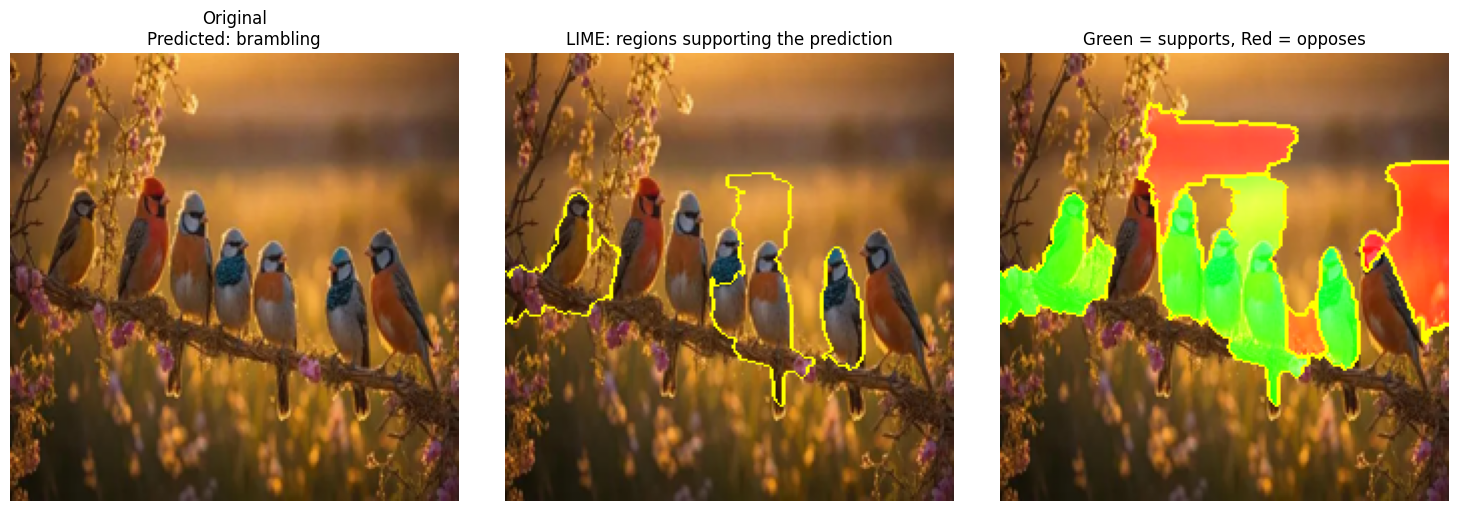

In [ ]:
label = explanation.top_labels[0]
name = class_names[label]

# (a) only the superpixels that SUPPORT the prediction
temp1, mask1 = explanation.get_image_and_mask(
    label, positive_only=True, num_features=5, hide_rest=False)

# (b) supporting (green) and opposing (red) superpixels
temp2, mask2 = explanation.get_image_and_mask(
    label, positive_only=False, num_features=10, hide_rest=False)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(img_pil); plt.title(f"Original\nPredicted: {name}"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(mark_boundaries(temp1, mask1)); plt.title("LIME: regions supporting the prediction"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(mark_boundaries(temp2, mask2)); plt.title("Green = supports, Red = opposes"); plt.axis("off")
plt.tight_layout(); plt.show()